# Execution-mode specificity controls

This notebook reruns the fixed five-fold controls for cross-benchmark CTF trace retrieval and presents the saved task-level results. The independent unit is the task group. These are post-hoc exploratory results: task identity is not attack-activity identity, and execution labels remain confounded with capture modality.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
while not (ROOT / "scripts" / "run_specificity_controls.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "scripts" / "run_specificity_controls.py").exists():
    raise FileNotFoundError("Open this notebook from a checkout of AttackAgentDetect")
os.chdir(ROOT)
print(f"Project: {ROOT}")

Project: /Users/mac/Documents/ChatGPT/APT画像/AttackAgentDetect


## Recompute the controls

The script verifies exact reproduction of the original 274 task/direction/method rows before writing the new control outputs. It uses the pinned local public-trace release; no network access or raw-log export is needed for this cell.

In [2]:
run = subprocess.run(
    [sys.executable, "scripts/run_specificity_controls.py"],
    check=True, capture_output=True, text=True,
)
results = json.loads((ROOT / "results/specificity_controls.json").read_text())
repro = results["original_reproduction"]
print(f"Original rows reproduced: {repro['task_direction_method_rows']}")
print(f"Maximum absolute metric difference: {repro['max_absolute_metric_difference']:.1f}")
print(f"Task groups: {results['audit']['tasks']}; records: {results['audit']['records']}")

Original rows reproduced: 274
Maximum absolute metric difference: 0.0
Task groups: 40; records: 177


## Human query → Agent gallery

The full gallery preserves the historical protocol, where held-out queries rank against all same-benchmark tasks. The strict gallery restricts both query and candidates to outer held-out tasks. Because the latter has fewer candidates and a higher random baseline, compare methods within a protocol; do not read its raw score as a direct improvement over the full-gallery score.

In [3]:
method_names = {
    "similarity_only": "Similarity only",
    "mode_aware": "Predicted execution mode",
    "length_conditioned": "Command-count control",
    "nonlinear_similarity": "Nonlinear similarity",
}
rows = []
for protocol, protocol_label in [("full_gallery", "Historical gallery"), ("heldout_gallery", "Held-out gallery")]:
    for method, label in method_names.items():
        item = results["retrieval"][f"{protocol}|human_agent|{method}"]
        recall = item["benchmark_macro"]["recall_at_1"]
        low, high = item["task_stratified_95_ci"]["recall_at_1"]
        rows.append({
            "Protocol": protocol_label, "Ranker": label, "Tasks": item["task_count"],
            "Recall@1": f"{recall:.3f} [{low:.3f}, {high:.3f}]",
            "MRR": f"{item['benchmark_macro']['mrr']:.3f}",
            "Query AUC": f"{item['benchmark_macro']['query_auc']:.3f}",
            "Mean candidates": f"{item['benchmark_macro']['candidate_tasks']:.1f}",
            "Random Recall@1": f"{item['benchmark_macro']['random_recall_at_1']:.3f}",
        })
display(pd.DataFrame(rows))

,Protocol,Ranker,Tasks,Recall@1,MRR,Query AUC,Mean candidates,Random Recall@1
0,Historical gallery,Similarity only,40,"0.346 [0.175, 0.528]",0.538,0.760,13.3,0.116
1,Historical gallery,Predicted execution mode,40,"0.414 [0.232, 0.596]",0.577,0.775,13.3,0.116
2,Historical gallery,Command-count control,40,"0.431 [0.243, 0.615]",0.588,0.776,13.3,0.116
3,Historical gallery,Nonlinear similarity,40,"0.369 [0.188, 0.551]",0.557,0.772,13.3,0.116
4,Held-out gallery,Similarity only,36,"0.638 [0.473, 0.787]",0.790,0.839,4.1,0.278
5,Held-out gallery,Predicted execution mode,36,"0.632 [0.470, 0.781]",0.787,0.837,4.1,0.278
6,Held-out gallery,Command-count control,36,"0.680 [0.507, 0.821]",0.791,0.813,4.1,0.278
7,Held-out gallery,Nonlinear similarity,36,"0.680 [0.502, 0.819]",0.810,0.852,4.1,0.278


## Paired mode-score contrasts

Paired differences use the same eligible query tasks. The interval resamples task groups within each benchmark and is conditional on fixed fitted folds and candidate sets.

In [4]:
contrast_names = {
    "mode_aware_minus_similarity_only": "Mode − similarity",
    "length_conditioned_minus_similarity_only": "Count − similarity",
    "nonlinear_similarity_minus_similarity_only": "Nonlinear − similarity",
    "mode_aware_minus_length_conditioned": "Mode − count",
}
rows = []
for protocol, protocol_label in [("full_gallery", "Historical gallery"), ("heldout_gallery", "Held-out gallery")]:
    for key, label in contrast_names.items():
        item = results["paired_deltas"][f"{protocol}|human_agent|{key}"]
        mean = item["mean_delta"]["recall_at_1"]
        low, high = item["task_stratified_95_ci"]["recall_at_1"]
        rows.append({"Protocol": protocol_label, "Contrast": label, "Tasks": item["task_count"],
                     "Δ Recall@1": f"{mean:+.3f} [{low:+.3f}, {high:+.3f}]"})
display(pd.DataFrame(rows))

,Protocol,Contrast,Tasks,Δ Recall@1
0,Historical gallery,Mode − similarity,40,"+0.068 [-0.012, +0.191]"
1,Historical gallery,Count − similarity,40,"+0.086 [-0.006, +0.213]"
2,Historical gallery,Nonlinear − similarity,40,"+0.024 [+0.000, +0.071]"
3,Historical gallery,Mode − count,40,"-0.018 [-0.071, +0.025]"
4,Held-out gallery,Mode − similarity,36,"-0.006 [-0.019, +0.000]"
5,Held-out gallery,Count − similarity,36,"+0.042 [-0.025, +0.127]"
6,Held-out gallery,Nonlinear − similarity,36,"+0.042 [+0.000, +0.125]"
7,Held-out gallery,Mode − count,36,"-0.048 [-0.131, +0.025]"


### Retrieval controls and paired task-level effects

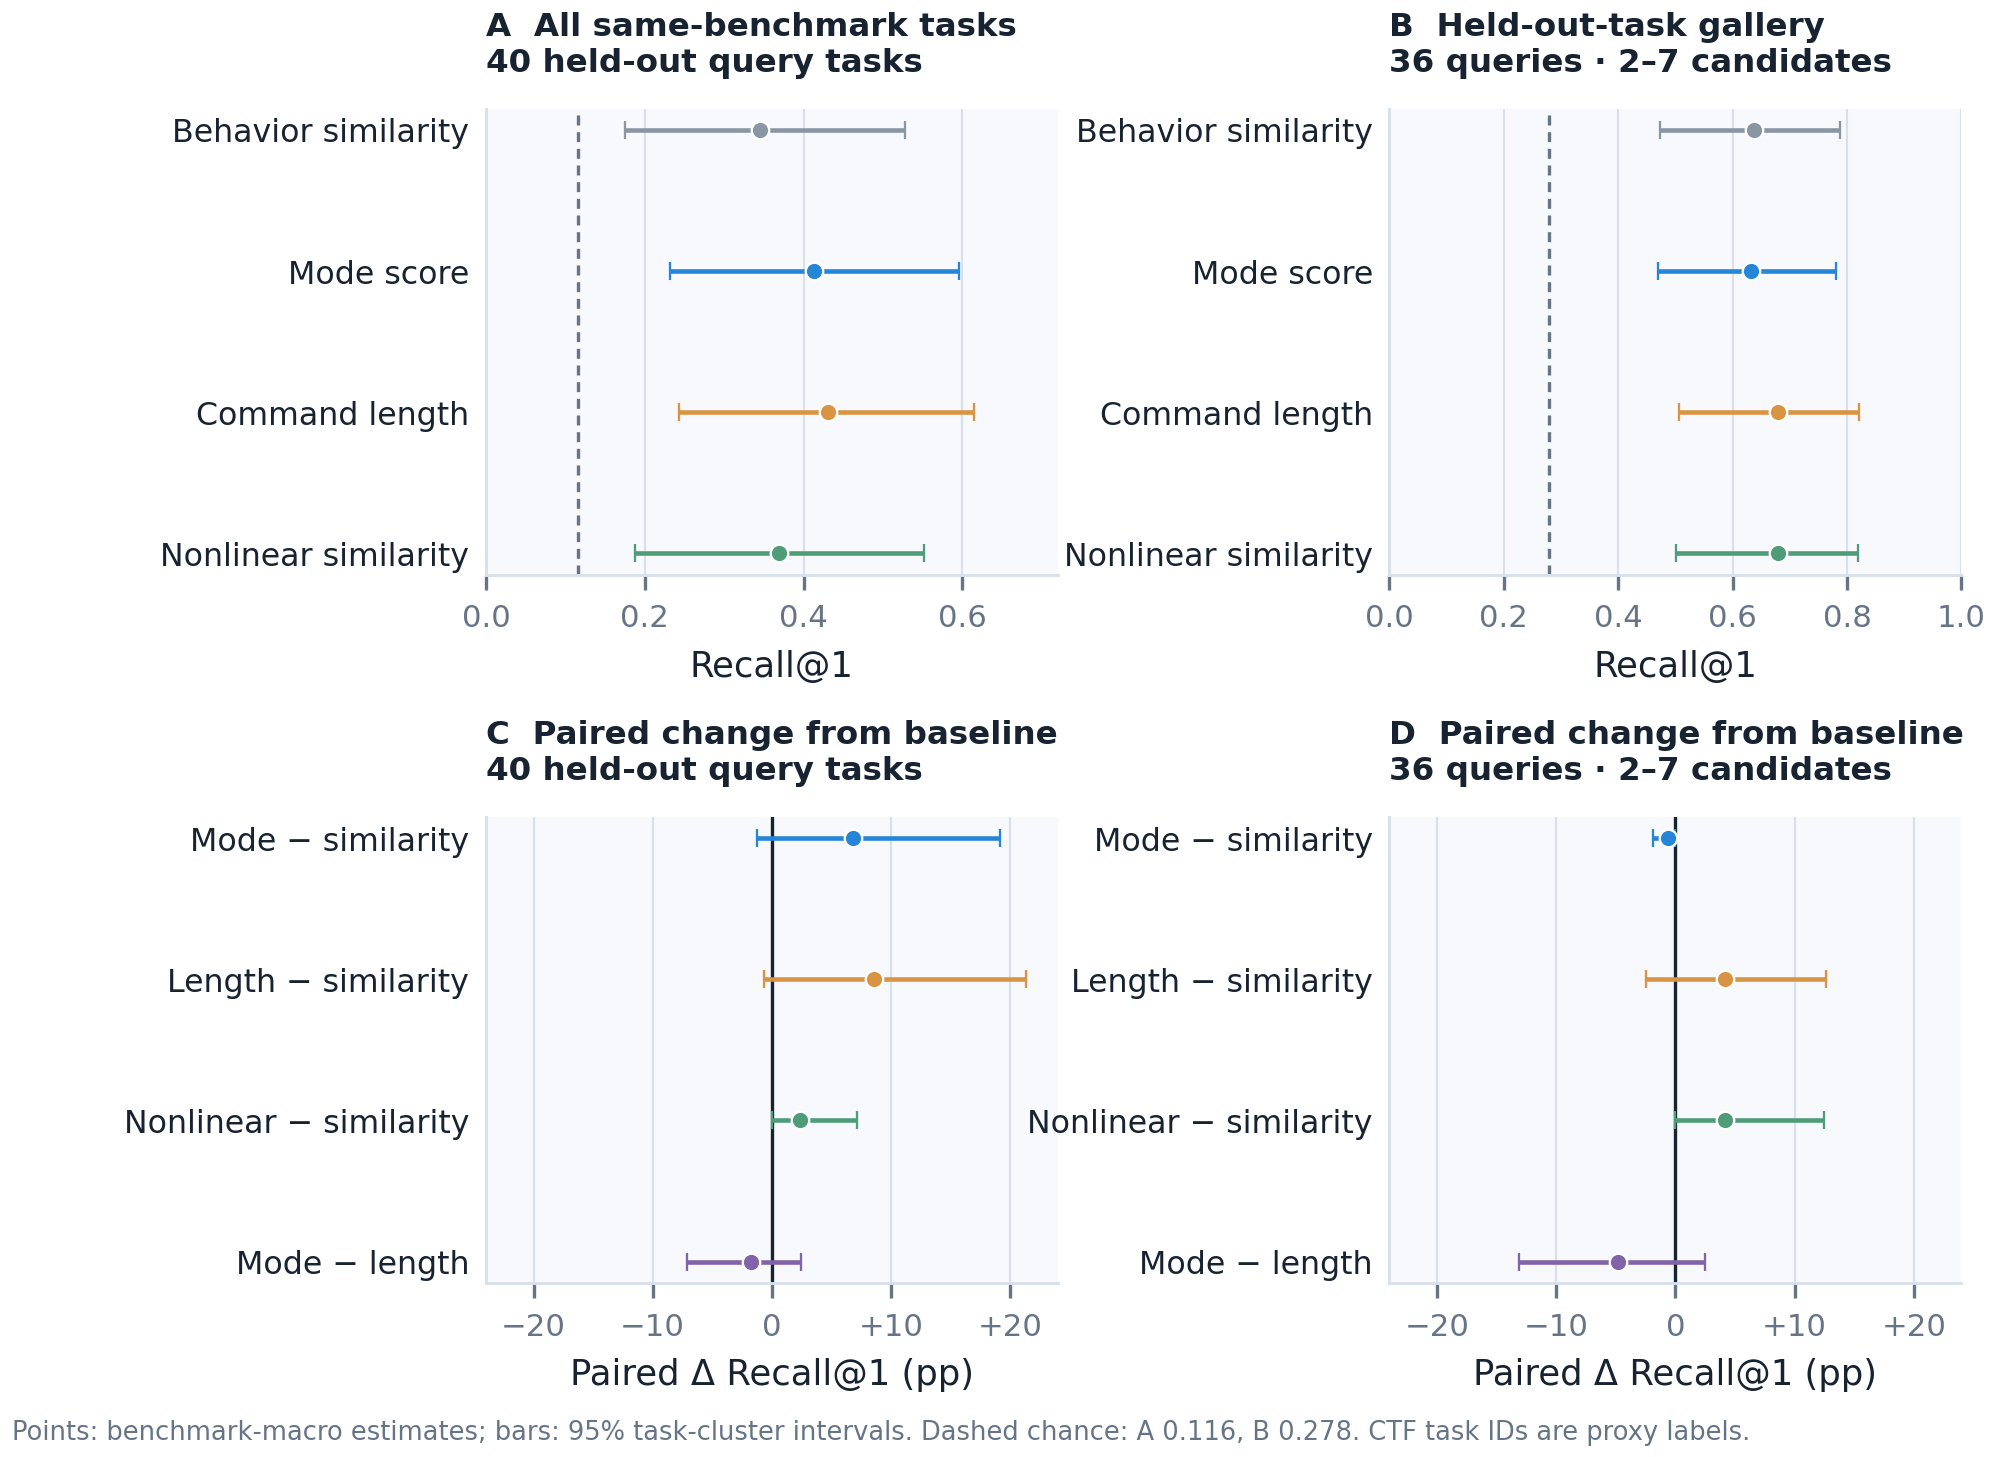

In [5]:
display(Markdown("### Retrieval controls and paired task-level effects"))
display(Image(filename=str(ROOT / "paper/figures/figure3_specificity_controls.png")))

### Mode-classification confusion heatmap

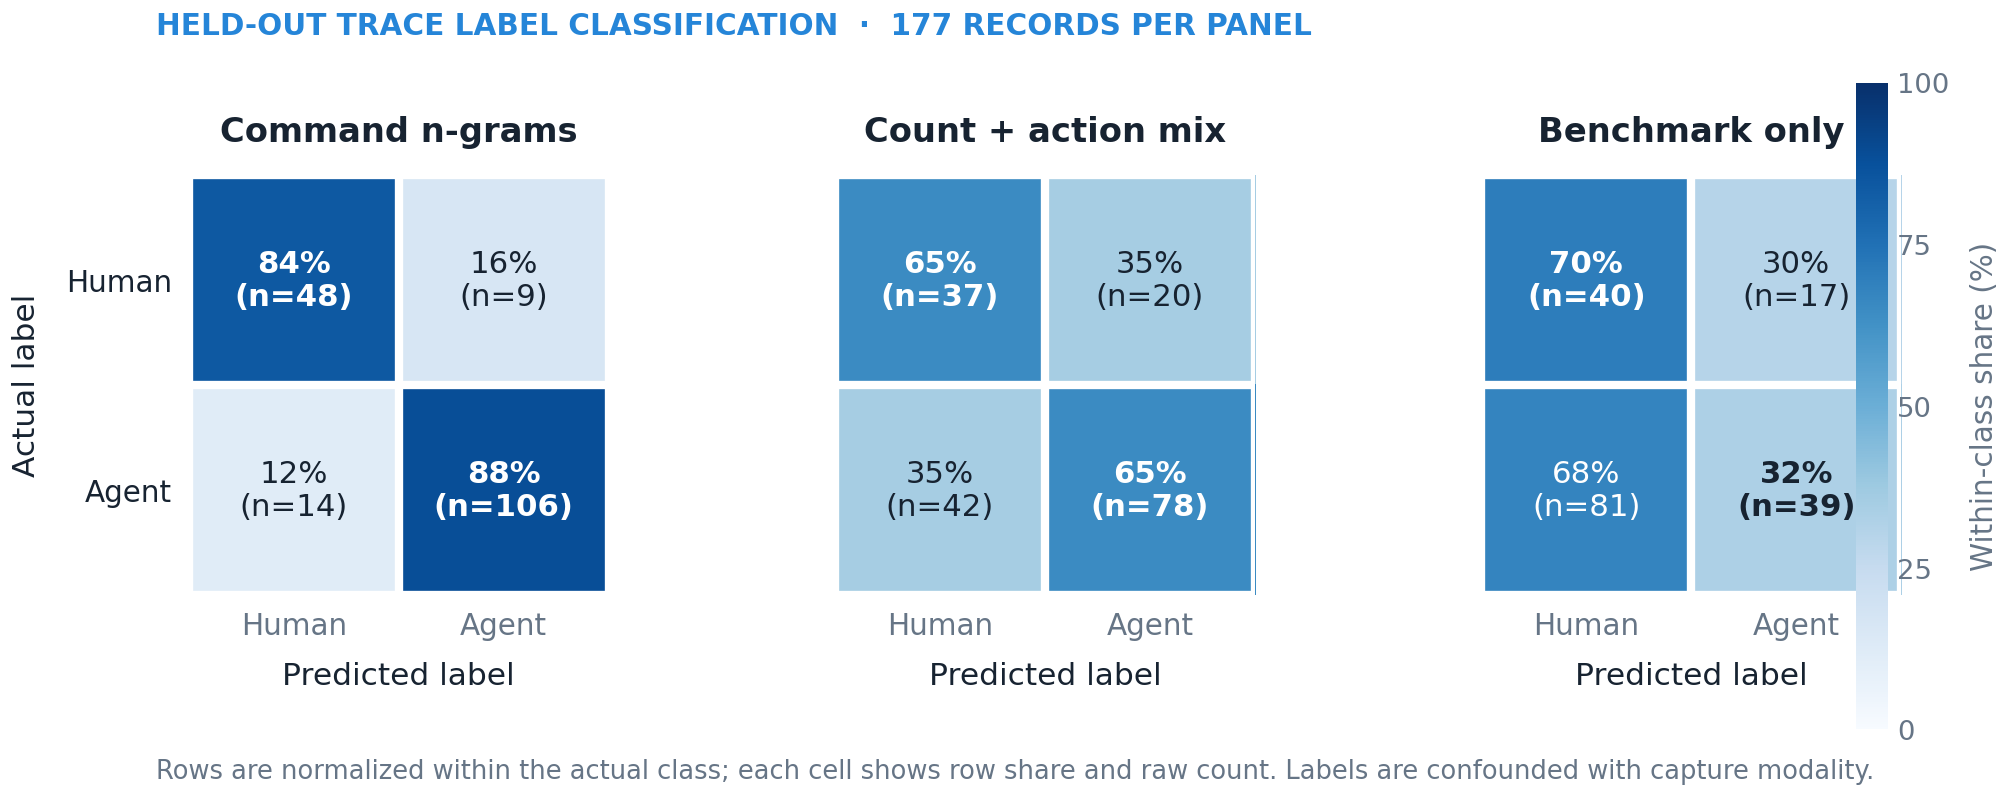

In [6]:
display(Markdown("### Mode-classification confusion heatmap"))
display(Image(filename=str(ROOT / "paper/figures/figureA4_mode_confusions.png")))

## Interpretation boundary

The predicted-mode ranker does not beat the command-count control in the historical gallery, and it is slightly below the similarity-only ranker in the held-out gallery. This supports the claim that label separability alone does not establish association utility. The current public records cannot show that Agent participation caused real APT activity links to split or merge: task IDs are CTF proxies, the capture pathways differ, and script traces are absent. The intervals also omit model refitting and candidate-gallery sampling uncertainty. A decisive causal test needs shared telemetry, independently varied human/script/Agent execution, and activity IDs assigned outside the feature pipeline.